# Séance 9 — Canevas du projet et préparation de la soutenance

Ce notebook n'est pas un atelier : c'est le **squelette de votre rendu**. Remplacez chaque
section par votre travail. La structure suit l'ordre de la soutenance, ce qui vous évite
de refaire le plan au dernier moment.

---

## Identification

| | |
|---|---|
| Groupe | *5 et noms* |
| Sujet | *Salle de sport* |
| Question traitée | *reprise de la fiche, ou reformulée si vous l'affinez* |
| Date de soutenance | *jour 5, après-midi* |

> **Format.** 15 minutes de présentation, 10 minutes de questions devant un jury unique.
> Les questions sont posées individuellement : chaque membre du groupe doit pouvoir
> répondre sur l'intégralité du travail, y compris les parties qu'il n'a pas présentées.
> **Dépôt du rendu : jour 5, 13 h 30.**

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [30]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  .~lock.capteurs.csv#
  Projets
  capteurs.csv
  clients.csv
  evenements_volumineux.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


> **Votre jeu de données vous est fourni.** Chaque groupe reçoit un domaine différent,
> avec ses propres anomalies : les chiffres, les pièges et les décisions à justifier ne
> sont pas les mêmes d'un groupe à l'autre. Comparer vos *méthodes* entre groupes est
> encouragé ; comparer vos *résultats* ne vous mènera nulle part.

> **Aucun sujet ne dit quelles anomalies son jeu contient.** Les trouver est la première
> partie du travail, et la première chose que le jury vérifiera. Commencez par appliquer
> votre `profile_dataframe` du jour 1 : elle a été écrite pour cela.

---
## 1. Contexte (2 min de présentation)

**À renseigner :** l'origine des données, ce qu'elles décrivent, la période couverte, et la
question à laquelle le jeu préparé doit permettre de répondre.

*Votre texte :*

In [31]:
# Chargement de la source brute. Aucun nettoyage à ce stade :
# on montre l'état initial, c'est lui qui donne sa valeur au travail qui suit.

# Indiquez ici le dossier de VOTRE groupe (voir la fiche Sujets de projet).
GROUP_DIR = ROOT / 'data'/'raw' / 'Projets' / 'groupe_05_salle'   # À ADAPTER

print('Fichiers reçus :')
for path in sorted(GROUP_DIR.glob('*.csv')):
    size_kb = path.stat().st_size / 1024
    print(f'  {path.name:<28} {size_kb:>8.0f} Ko')
    
seances = pd.read_csv(GROUP_DIR / 'seances.csv')
salles = pd.read_csv(GROUP_DIR / 'salles.csv')
adherents = pd.read_csv(GROUP_DIR / 'adherents.csv')
frequentation_salles = pd.read_csv(GROUP_DIR / 'frequentation_salles.csv')
activites = pd.read_csv(GROUP_DIR / 'activites.csv')
#print(seances.shape, salle.shape, adherents.shape, frequentations_salle.shape, activites.shape )
display(seances.head())
display(salles.head())
display(adherents.head())
display(frequentation_salles.head())
display(activites.head())





# La table principale est la plus volumineuse : les autres sont des référentiels.
# TODO : charger la table de faits et les référentiels, puis afficher un head()

Fichiers reçus :
  activites.csv                       3 Ko
  adherents.csv                     135 Ko
  frequentation_salles.csv          772 Ko
  salles.csv                          1 Ko
  seances.csv                      1885 Ko


,id_seance,date_evenement,id_adherent,id_activite,id_salle,duree_min,calories_estimees,tarif_seance_eur,reservation,statut
0,SEA0003825,18 Feb 2024,ADH02225,ACT0022,SAL09,110,882.0,12.49,ACCUEIL,realisee
1,SEA0019108,2024-12-17,ADH01715,ACT0035,SAL05,71,526.0,19.81,accueil,REALISEE
2,SEA0017394,2024-10-23,ADH00177,ACT0029,SAL03,33,585.0,5.46,accueil,realisee
3,SEA0015045,04-08-2024,ADH00947,ACT0014,SAL09,115,112.0,15.34,application,realisee
4,SEA0019984,12-09-2024,ADH01094,ACT0008,SAL01,38,409.0,16.37,application,realisee


,id_salle,nom_site,ville,region,capacite
0,SAL01,Site Paris,Paris,Ile-de-France,634
1,SAL02,Site Lyon,Lyon,Auvergne-Rhone-Alpes,172
2,SAL03,Site Marseille,Marseille,PACA,114
3,SAL04,Site Lille,Lille,Hauts-de-France,883
4,SAL05,Site Bordeaux,Bordeaux,Nouvelle-Aquitaine,408


,id_adherent,date_creation,segment,ville,age
0,ADH00001,2019-06-14,association,Bordeaux,38.0
1,ADH00002,2023-09-08,association,Montpellier,33.0
2,ADH00003,2021-09-20,professionnel,Strasbourg,52.0
3,ADH00004,2020-01-24,particulier,Strasbourg,16.0
4,ADH00005,2021-06-13,professionnel,Montpellier,45.0


,horodatage,id_point,nb_presents,temperature_c
0,2024-01-01 00:00:00,P-01,27.14,3.7
1,2024-01-01 01:00:00,P-01,23.02,4.7
2,2024-01-01 02:00:00,P-01,26.57,3.3
3,2024-01-01 03:00:00,P-01,23.45,5.3
4,2024-01-01 04:00:00,P-01,26.71,5.9


,id_activite,libelle,famille,sous_famille,cout_reference_eur
0,ACT0001,Sea-0001,Famille B,Famille B / variante 2,418.38
1,ACT0002,Sea-0002,Famille C,Famille C / variante 3,276.19
2,ACT0003,Sea-0003,Famille D,Famille D / variante 4,55.32
3,ACT0004,Sea-0004,Famille E,Famille E / variante 5,23.48
4,ACT0005,Sea-0005,Famille A,Famille A / variante 6,231.80


---
## 2. Diagnostic (3 min)

Appliquez votre fonction `profile_dataframe` de la séance 2, puis **quantifiez** chaque
anomalie. Un diagnostic sans chiffre n'est pas un diagnostic.

In [32]:
import sys
sys.path.insert(0, str(ROOT / 'src'))

from exploration import profile_dataframe
profile_dataframe(seances, name='seances.csv')

=== seances.csv ===
Dimensions : 23567 lignes × 10 colonnes
Mémoire : 10.84 MB

Lignes dupliquées : 260

--- Profil des colonnes ---
                      type  valeurs_manquantes  taux_manquants_%  valeurs_distinctes
id_seance           object                   0              0.00               23307
date_evenement      object                 473              2.01                6007
id_adherent         object                   0              0.00                2899
id_activite         object                   0              0.00                  60
id_salle            object                   0              0.00                  11
duree_min            int64                   0              0.00                 107
calories_estimees  float64                3056             12.97                 811
tarif_seance_eur   float64                   0              0.00                3429
reservation         object                   0              0.00                   9
statut           

Tableau des anomalies
| Anomalie | Colonne | Ampleur | Gravité | Traitement retenu |
|---|---|---|---|---|
|lignes duppliqés  | toutes le colonnes | 260 |  |Supprimer les doublons exacts avec dropDuplicates()  |
|valeurs manquantes   |date_evenment  | 473 |  | Vérifier les dates sources ; conserver les valeurs manquantes ou supprimer les lignes selon leur utilité pour l'analyse |
| valeurs manquantes | calories_estimes | 3056 |  | Conserver les valeurs manquantes si le calcul des calories n'est pas indispensable ; sinon, étudier une méthode d'imputation adaptée |
| Dates invalides ou mal formatées | date_evenement  |  |  | Convertir les dates au bon format et repérer les dates devenues nulles |

---
## 3. Traitements (5 min — la partie la plus longue de la soutenance)

Pour chaque décision, trois éléments sont attendus : **ce que vous avez fait**, **pourquoi**,
et **quelle alternative vous avez écartée**. Le troisième point est celui qui fait la
différence à l'oral.

In [37]:
# Pipeline de nettoyage et de transformation

# Pipeline de nettoyage — table seances
df = seances.copy()
n_start = len(df)

# 1. Texte : enlever les espaces et tout mettre en minuscules
df['reservation'] = df['reservation'].str.strip().str.lower()
df['statut'] = df['statut'].str.strip().str.lower()
df['reservation'] = df['reservation'].replace(['?', 'na', 'n/a', 'null', '-', ''], np.nan)
df['statut'] = df['statut'].replace(['?', 'na', 'n/a', 'null', '-', ''], np.nan)
print('1. Réservation :', df['reservation'].dropna().unique().tolist())
print('   Statut      :', df['statut'].dropna().unique().tolist())

# 2. Dates : la source mélange 3 formats, on les essaie un par un
dates_texte = df['date_evenement'].str.strip()
format_iso = pd.to_datetime(dates_texte, format='%Y-%m-%d', errors='coerce')     # 2024-12-17
format_fr = pd.to_datetime(dates_texte, format='%d-%m-%Y', errors='coerce')      # 04-08-2024
format_mois = pd.to_datetime(dates_texte, format='%d %b %Y', errors='coerce')    # 18 Feb 2024
df['date_evenement'] = format_iso.fillna(format_fr).fillna(format_mois)
print('2. Dates non reconnues :', df['date_evenement'].isna().sum())

# 3. Nombres : s'assurer que ce sont bien des nombres
for col in ['duree_min', 'calories_estimees', 'tarif_seance_eur']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 4. Doublons
print('4. Doublons supprimés :', df.duplicated().sum())
df = df.drop_duplicates()
df = df.drop_duplicates(subset='id_seance')

# 5. Valeurs impossibles → vides
futures = df['date_evenement'] > pd.Timestamp.today()
df.loc[futures, 'date_evenement'] = pd.NaT
print('5. Dates futures vidées :', futures.sum())
for col in ['duree_min', 'calories_estimees', 'tarif_seance_eur']:
    negatifs = df[col] < 0
    df.loc[negatifs, col] = np.nan
    print(f'   {col} négatifs vidés :', negatifs.sum())

# 6. Remplir les vides (on garde la trace avant)
for col in ['duree_min', 'calories_estimees', 'tarif_seance_eur']:
    df[col + '_was_missing'] = df[col].isna()
    df[col] = df[col].fillna(df[col].median())
for col in ['reservation', 'statut']:
    df[col + '_was_missing'] = df[col].isna()
    df[col] = df[col].fillna('inconnu')

# 7. Jointures avec les référentiels (on garde toutes les séances)
#    Les salles d'abord : la colonne « ville » est celle de la salle.
df = df.merge(salles.drop_duplicates(subset='id_salle'), on='id_salle',
              how='left', indicator=True)
df['flag_orphelin_id_salle'] = df['_merge'] == 'left_only'
df = df.drop(columns='_merge')
print('7. Séances sans salle connue :', df['flag_orphelin_id_salle'].sum(),
      '| identifiants :', df.loc[df['flag_orphelin_id_salle'], 'id_salle'].unique().tolist())

df = df.merge(activites.drop_duplicates(subset='id_activite'), on='id_activite',
              how='left', suffixes=('', '_activite'))

df = df.merge(adherents.drop_duplicates(subset='id_adherent'), on='id_adherent',
              how='left', suffixes=('', '_adherent'), indicator=True)
df['flag_orphelin_id_adherent'] = df['_merge'] == 'left_only'
df = df.drop(columns='_merge')
print('   Séances sans adhérent connu :', df['flag_orphelin_id_adherent'].sum())

# TODO

1. Réservation : ['accueil', 'application', 'sans_reservation']
   Statut      : ['realisee', 'no_show', 'annulee']
2. Dates non reconnues : 14332
4. Doublons supprimés : 260
5. Dates futures vidées : 0
   duree_min négatifs vidés : 38
   calories_estimees négatifs vidés : 0
   tarif_seance_eur négatifs vidés : 0
7. Séances sans salle connue : 0 | identifiants : []
   Séances sans adhérent connu : 0


| Décision | Justification | Alternative écartée | Motif du rejet |
|---|---|---|---|
| Supprimer les espaces inutiles et convertir reservation et statut en minuscules |  |Conserver les valeurs originales  |  |
| Remplacer ?, na, n/a, null, - et les chaînes vides par des valeurs manquantes |  |  Conserver ces chaînes telles quelles|  |
| Conserver les dates non reconnues comme valeurs manquantes (NaT) |  |  Conserver les valeurs textuelles|  |
| Supprimer les doublons exacts, puis les doublons selon id_seance |  |  Conserver ces chaînes telles quelles|  |
| Remplacer les valeurs numériques manquantes par la médiane |  |  Supprimer les lignes incomplètes ou utiliser la moyenne|  |

|Remplacer les catégories manquantes par inconnu |  |  Supprimer les lignes ou utiliser la catégorie majoritaire|  |



---
## 4. Composant PySpark (2 min)

Quelle étape avez-vous portée sur Spark, et **pourquoi celle-là** ? Chiffrez : volume
traité, durée, mémoire. Rappel de la séance 7 : « parce que c'est plus rapide » est une
réponse fausse sur une machine unique.

In [34]:
import os
import time

import psutil
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

SEANCES_PATH = GROUP_DIR / 'seances.csv'
CATEGORY_COLS = ['reservation', 'statut']
DATE_FORMATS = ['yyyy-MM-dd', 'dd-MM-yyyy', 'dd/MM/yyyy', 'd MMM yyyy']


def total_memory_mb():
    # Python + JVM Spark : Spark tourne dans un processus enfant de Python
    process = psutil.Process(os.getpid())
    processes = [process] + process.children(recursive=True)
    return sum(p.memory_info().rss for p in processes) / 1024 ** 2


# 1. Démarrage de la session, mesuré à part
start = time.perf_counter()
spark = (SparkSession.builder
         .appName('projets')
         .master('local[*]')
         .config('spark.sql.ansi.enabled', 'false')                # date illisible → null, pas d'erreur
         .config('spark.sql.legacy.timeParserPolicy', 'CORRECTED')  # parseur de dates strict
         .getOrCreate())
startup_seconds = time.perf_counter() - start

# 2. Étape portée sur Spark : nettoyage du texte, dédoublonnage, dates multi-formats
memory_before = total_memory_mb()
start = time.perf_counter()

spark_df = spark.read.csv(str(SEANCES_PATH), header=True)   # lecture directe du fichier source
n_start = spark_df.count()

for col_name in spark_df.columns:
    spark_df = spark_df.withColumn(col_name, F.trim(F.col(col_name)))
for col_name in CATEGORY_COLS:
    spark_df = spark_df.withColumn(col_name, F.lower(F.col(col_name)))
spark_df = spark_df.dropDuplicates()
spark_df = spark_df.withColumn('date_evenement', F.coalesce(
    *[F.to_date(F.col('date_evenement'), fmt) for fmt in DATE_FORMATS]))

n_final = spark_df.count()             # action : c'est ici que Spark calcule réellement
spark_seconds = time.perf_counter() - start
spark_memory = total_memory_mb() - memory_before
n_unparsed = spark_df.filter(F.col('date_evenement').isNull()).count()


print('MESURES PYSPARK')
print(f'Fichier traité          : seances.csv ({SEANCES_PATH.stat().st_size / 1024 ** 2:.2f} Mo)')
print(f'Lignes initiales        : {n_start}')
print(f'Lignes après traitement : {n_final}')
print(f'Doublons supprimés      : {n_start - n_final}')
print(f'Dates non reconnues     : {n_unparsed}')
print(f'Démarrage de la session : {startup_seconds:.2f} s')
print(f"Durée de l'étape        : {spark_seconds:.2f} s")
print(f'Mémoire (Python + JVM)  : {spark_memory:+.1f} Mo')

display(spark_df.limit(5).toPandas())

MESURES PYSPARK
Fichier traité          : seances.csv (1.84 Mo)
Lignes initiales        : 23567
Lignes après traitement : 23307
Doublons supprimés      : 260
Dates non reconnues     : 5040
Démarrage de la session : 0.01 s
Durée de l'étape        : 1.43 s
Mémoire (Python + JVM)  : +27.5 Mo


,id_seance,date_evenement,id_adherent,id_activite,id_salle,duree_min,calories_estimees,tarif_seance_eur,reservation,statut
0,SEA0004008,None,ADH02253,ACT0018,SAL06,109,177.0,17.95,application,annulee
1,SEA0010758,2024-01-23,ADH01156,ACT0021,SAL07,45,150.0,12.87,application,realisee
2,SEA0006560,2024-04-30,ADH01798,ACT0044,SAL10,43,448.0,8.4,application,annulee
3,SEA0023996,2024-12-16,ADH01279,ACT0059,SAL06,61,267.0,28.35,application,realisee
4,SEA0010737,2024-12-21,ADH02076,ACT0030,SAL10,26,299.0,19.36,sans_reservation,realisee


---
## 5. Résultat (3 min)

Le jeu final, sa structure, les indicateurs, la planche de visualisation, et les limites
que vous assumez. **Énoncer soi-même les limites de son travail est valorisé** : cela
montre que vous savez où il ne faut pas faire confiance à vos données.

=== CONTRÔLES ===
aucun doublon exact                      OK
id_seance unique                         OK
aucune date future                       OK
aucune valeur négative                   OK
aucun vide dans les colonnes imputées    OK
au moins 90 % des lignes conservées      OK
moins de 5 % de dates manquantes         À EXAMINER

=== INDICATEURS ===
Lignes                  : 23567 -> 23307
Colonnes                : 10 -> 29
Période couverte        : 01/01/2024 -> 30/12/2024
Dates manquantes        : 60.9%
Adhérents distincts     : 2899
Répartition des statuts : {'realisee': 15660, 'no_show': 3850, 'annulee': 3797}
Durée moyenne           : 69 min
Chiffre d'affaires      : 231,225 € (séances réalisées)
Séances sans salle connue   : 0 (0.0%)
Séances sans adhérent connu : 0 (0.0%)

Taux de statut par canal de réservation (%) :
statut            annulee  no_show  realisee
reservation                                 
accueil              16.2     16.0      67.8
application          16.4 

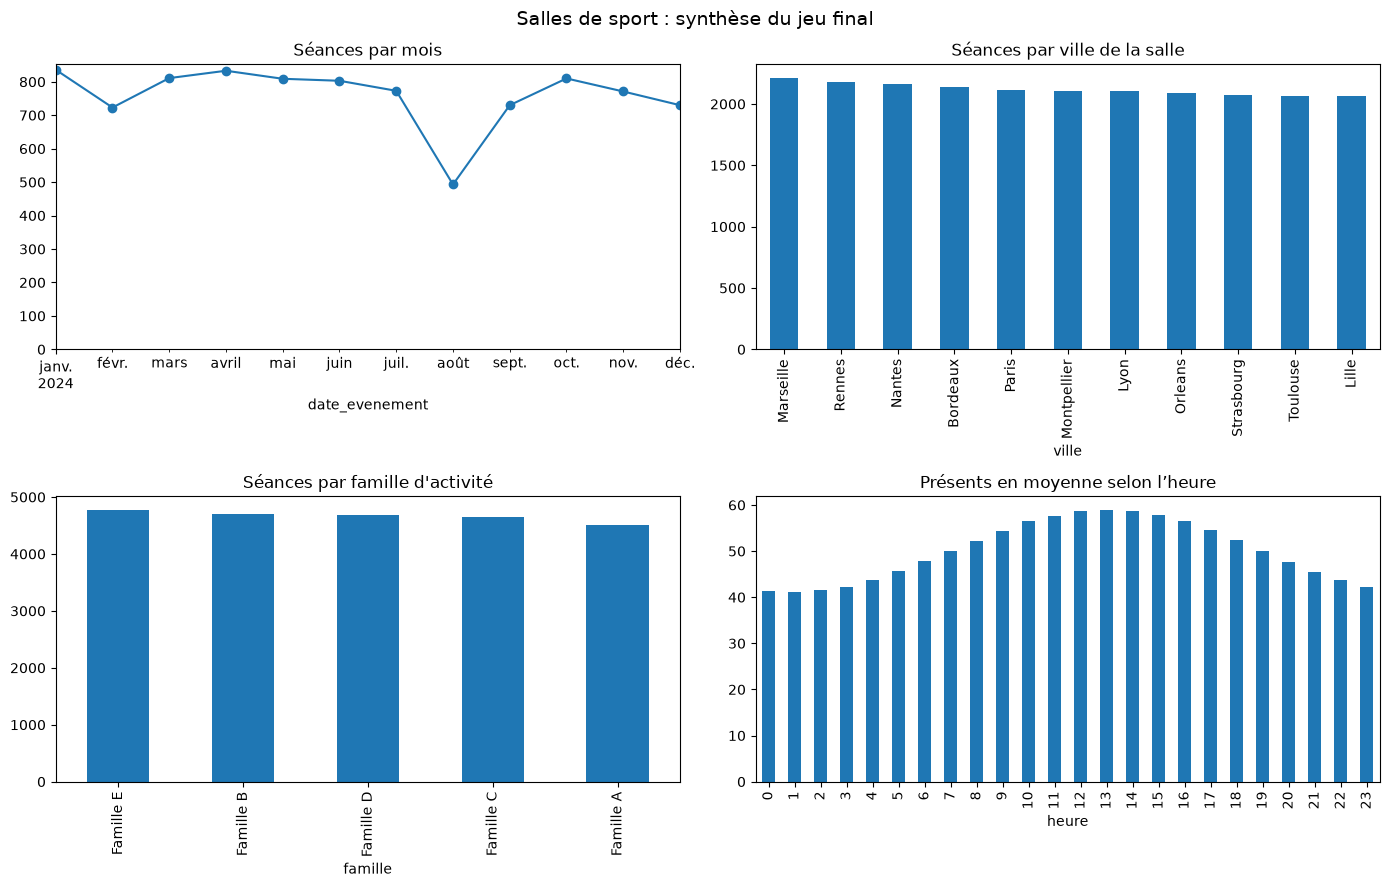

In [39]:
import matplotlib.pyplot as plt

NUMERIC_COLS = ['duree_min', 'calories_estimees', 'tarif_seance_eur']
CATEGORY_COLS = ['reservation', 'statut']

final = load_dataset('seances_clean')
final['date_evenement'] = pd.to_datetime(final['date_evenement'])   # le CSV perd le type date

# Repères d'orphelins : séances dont la salle ou l'adhérent n'existe pas dans le référentiel
final['flag_orphelin_id_salle'] = ~final['id_salle'].isin(salles['id_salle'])          # SAL99
final['flag_orphelin_id_adherent'] = ~final['id_adherent'].isin(adherents['id_adherent'])

# 1. Contrôles de cohérence
checks = {
    'aucun doublon exact': not final.duplicated().any(),
    'id_seance unique': final['id_seance'].is_unique,
    'aucune date future': (final['date_evenement'].isna()
                           | (final['date_evenement'] <= pd.Timestamp.today())).all(),
    'aucune valeur négative': (final[NUMERIC_COLS] >= 0).all().all(),
    'aucun vide dans les colonnes imputées': final[NUMERIC_COLS + CATEGORY_COLS].notna().all().all(),
    'au moins 90 % des lignes conservées': len(final) >= 0.9 * len(seances),
    'moins de 5 % de dates manquantes': final['date_evenement'].isna().mean() < 0.05,
}
print('=== CONTRÔLES ===')
for label, ok in checks.items():
    print(f'{label:<40} {"OK" if ok else "À EXAMINER"}')

# 2. Indicateurs
realised = final[final['statut'] == 'realisee']
print('\n=== INDICATEURS ===')
print(f"Lignes                  : {len(seances)} -> {len(final)}")
print(f"Colonnes                : {seances.shape[1]} -> {final.shape[1]}")
print(f"Période couverte        : {final['date_evenement'].min():%d/%m/%Y} -> "
      f"{final['date_evenement'].max():%d/%m/%Y}")
print(f"Dates manquantes        : {final['date_evenement'].isna().mean():.1%}")
print(f"Adhérents distincts     : {final['id_adherent'].nunique()}")
print(f"Répartition des statuts : {final['statut'].value_counts().to_dict()}")
print(f"Durée moyenne           : {final['duree_min'].mean():.0f} min")
print(f"Chiffre d'affaires      : {realised['tarif_seance_eur'].sum():,.0f} € (séances réalisées)")
print(f"Séances sans salle connue   : {final['flag_orphelin_id_salle'].sum()} "
      f"({final['flag_orphelin_id_salle'].mean():.1%})")
print(f"Séances sans adhérent connu : {final['flag_orphelin_id_adherent'].sum()} "
      f"({final['flag_orphelin_id_adherent'].mean():.1%})")
print('\nTaux de statut par canal de réservation (%) :')
print((pd.crosstab(final['reservation'], final['statut'], normalize='index') * 100).round(1))

# 3. Planche de visualisation
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Salles de sport : synthèse du jeu final', fontsize=14)

(final['date_evenement'].dt.to_period('M').value_counts().sort_index()
    .plot(ax=axes[0, 0], marker='o', title='Séances par mois'))
axes[0, 0].set_ylim(bottom=0)       # axe à zéro : ne pas exagérer les variations
final['ville'].fillna('salle inconnue (SAL99)').value_counts().plot.bar(
    ax=axes[0, 1], title='Séances par ville de la salle')
final['famille'].value_counts().plot.bar(ax=axes[1, 0], title="Séances par famille d'activité")

if dataset_exists('frequentation_clean'):
    freq_final = load_dataset('frequentation_clean')
    freq_final['horodatage'] = pd.to_datetime(freq_final['horodatage'])
    (freq_final.groupby(freq_final['horodatage'].dt.hour)['nb_presents'].mean()
        .plot.bar(ax=axes[1, 1], title='Présents en moyenne selon l’heure'))
    axes[1, 1].set_xlabel('heure')
else:
    axes[1, 1].axis('off')          # pas de fréquentation nettoyée : case vide plutôt qu'un graphique faux

plt.tight_layout()
plt.savefig(ROOT / 'planche_synthese.png', dpi=120)
plt.show()

Limites assumées

1. Un taux élevé de dates manquantes
2. L’imputation des valeurs manquantes
3. Une estimation du chiffre d’affaires

---
## 6. Contrôle avant dépôt

La cellule suivante vérifie que votre rendu est complet. Exécutez-la avant de déposer.

Le dépôt est attendu le **jour 5 à 13 h 30**, avant la reprise de l'après-midi : votre
composant PySpark se termine le matin même. Prévoyez trente minutes pour la mise en forme,
pas cinq.

In [40]:
checks = {
    'requirements.txt présent': (ROOT / 'requirements.txt').exists(),
    'README.md présent': (ROOT / 'README.md').exists(),
    'dossier src/ non vide': (ROOT / 'src').exists() and any((ROOT / 'src').glob('*.py')),
    'jeu final produit': (any(PROCESSED_DIR.glob('*.parquet'))
                          or any(PROCESSED_DIR.glob('*.csv'))),
    'note méthodologique': any(ROOT.glob('note_methodologique.*')),
    'support de soutenance': any(ROOT.glob('soutenance.*')),
}

width = max(len(label) for label in checks)
for label, is_ok in checks.items():
    print(f"{label:<{width}}  {'OK' if is_ok else 'MANQUANT'}")

if all(checks.values()):
    print('\nRendu complet.')
else:
    print('\nIl manque des éléments listés ci-dessus.')

requirements.txt présent  OK
README.md présent         MANQUANT
dossier src/ non vide     OK
jeu final produit         OK
note méthodologique       MANQUANT
support de soutenance     MANQUANT

Il manque des éléments listés ci-dessus.


---
## 7. Préparation aux questions

Rédigez votre réponse à chacune de ces questions **avant** la soutenance. Elles seront
posées dans une formulation proche.

1. Pourquoi avoir imputé cette colonne de cette façon plutôt qu'autrement ?
2. Vous avez écarté un certain pourcentage de lignes. Comment savez-vous qu'il ne
   s'agissait pas d'observations légitimes ?
3. Combien de colonnes votre encodage a-t-il produit ? Quelles conséquences ?
4. À partir de quel volume votre pipeline Pandas cesserait-il de fonctionner ?
5. Si je vous fournis demain un nouveau fichier source au même format, que faut-il faire ?
6. Montrez-moi la ligne de code qui traite ce cas particulier et expliquez-la.
7. Quelle est la principale limite de votre jeu de données final ?

> **Chaque membre du groupe doit pouvoir répondre sur l'intégralité du travail**, y compris
> les parties qu'il n'a pas présentées. Les questions sont posées individuellement.